In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from fredapi import Fred
import yfinance as yf

## Data Collection

Data for this project will be obtained from FRED (Federal Reserve Economic Data), Yahoo Finance APIs, and historical CSV files for indicators where API coverage does not extend back to 1960. The following macroeconomic and financial indicators will be examined:

### FRED Indicators
- **Unemployment Rate (UNRATE)** - monthly measure of the percentage of the labour force that is unemployed, a key lagging indicator of economic health
- **Consumer Price Index (CPIAUCSL)** - measures inflation through changes in the price of a basket of consumer goods and services
- **Federal Funds Rate (FEDFUNDS)** - the interest rate at which banks lend to each other overnight, a primary tool of US monetary policy
- **Industrial Production (INDPRO)** - measures real output of the manufacturing, mining and utilities sectors, a leading indicator of economic activity
- **House Prices (CSUSHPISA)** - S&P CoreLogic Case-Shiller US National Home Price Index, captures housing market conditions; available from 1987
- **Yield Curve (T10Y2Y)** - spread between 10-year and 2-year Treasury yields; inversion has preceded every US recession since the 1950s; available from 1976
- **Initial Jobless Claims (ICSA)** - weekly count of new unemployment insurance claims, one of the most timely labour market indicators available; available from 1967
- **Credit Spread (BAA10Y)** - spread between Moody's BAA corporate bond yield and 10-year Treasury yield; widens as default risk rises ahead of recessions; available from 1986
- **Consumer Credit (TOTALSL)** - total outstanding consumer credit, captures household borrowing trends
- **Housing Starts (HOUST)** - number of new residential construction projects begun each month, a forward-looking indicator of economic activity
- **30-Year Fixed Mortgage Rate (MORTGAGE30US)** - captures consumer borrowing costs in the housing market; available from 1971
- **Money Supply M2 (M2SL)** - broad measure of money supply including cash, deposits and money market funds; changes in M2 often precede turning points in economic activity
- **Federal Debt as % of GDP (GFDEGDQ188S)** - captures long-term fiscal sustainability; quarterly series interpolated to monthly frequency; available from 1966
- **Corporate Profits (CP)** - pre-tax corporate profits, a leading indicator of business investment and hiring decisions; quarterly series interpolated to monthly frequency
- **Recession Indicator (USREC)** - NBER defined binary indicator, 1 during recession months and 0 otherwise; used as the target variable

### Yahoo Finance and CSV Indicators
- **S&P 500 (^GSPC)** - broad measure of US equity market performance, reflects investor expectations about future economic conditions; extended back to 1960 using historical CSV data combined with Yahoo Finance API
- **Gold** - commodity price commonly associated with safe haven demand during periods of economic uncertainty; extended back to 1960 using historical CSV data combined with Yahoo Finance API


In [2]:
# FRED API Connection

FRED_API_KEY = "99a4258f3c059800db6f3473af4d2edf"
fred = Fred(api_key=FRED_API_KEY)

In [3]:
# Start & End Dates for Project

START = "1960-01-01"
END   = pd.Timestamp.today().strftime("%Y-%m-%d")

In [4]:
# FRED Indicators 

unemployment          = fred.get_series("UNRATE",       START, END)
cpi                   = fred.get_series("CPIAUCSL",     START, END)
fed_funds             = fred.get_series("FEDFUNDS",     START, END)
industrial_production = fred.get_series("INDPRO",       START, END)
house_prices          = fred.get_series("CSUSHPISA",    START, END)
recession             = fred.get_series("USREC",        START, END)
yield_curve           = fred.get_series("T10Y2Y",       START, END)
jobless_claims        = fred.get_series("ICSA",         START, END)
credit_spread         = fred.get_series("BAA10Y",       START, END)
consumer_credit       = fred.get_series("TOTALSL",      START, END)
lei                   = fred.get_series("USSLIND",      START, END)
housing_starts        = fred.get_series("HOUST",        START, END)
mortgage_rates        = fred.get_series("MORTGAGE30US", START, END)
debt_gdp              = fred.get_series("GFDEGDQ188S",  START, END)
corporate_profits     = fred.get_series("CP",           START, END)
m2                    = fred.get_series("M2SL",         START, END)

print("FRED data collected")

FRED data collected


In [5]:
# Yahoo Finance Indicators 

sp500_raw  = yf.download("^GSPC",  start=START, end=END, interval="1mo", progress=False)
gold_raw   = yf.download("GC=F",   start=START, end=END, interval="1mo", progress=False)
vix_raw    = yf.download("^VIX",   start=START, end=END, interval="1mo", progress=False)

sp500  = sp500_raw["Close"].squeeze()
gold   = gold_raw["Close"].squeeze()
vix    = vix_raw["Close"].squeeze()

print("Yahoo Finance data collected")

Yahoo Finance data collected


In [6]:
# Align to Monthly Frequency 
# resample all series to month start, forward fill where needed

def to_monthly(series, label):
    s = series.copy()
    s.index = pd.to_datetime(s.index)
    s = s.resample("MS").mean()
    s.name = label
    return s

unemployment          = to_monthly(unemployment,          "unemployment")
cpi                   = to_monthly(cpi,                   "cpi")
fed_funds             = to_monthly(fed_funds,             "fed_funds")
industrial_production = to_monthly(industrial_production, "industrial_production")
house_prices          = to_monthly(house_prices,          "house_prices")
recession             = to_monthly(recession,             "recession")
yield_curve           = to_monthly(yield_curve,           "yield_curve")
jobless_claims        = to_monthly(jobless_claims,        "jobless_claims")
credit_spread         = to_monthly(credit_spread,         "credit_spread")
consumer_credit       = to_monthly(consumer_credit,       "consumer_credit")
lei                   = to_monthly(lei,                   "lei")
housing_starts        = to_monthly(housing_starts,        "housing_starts")
mortgage_rates        = to_monthly(mortgage_rates,        "mortgage_rates")
sp500                 = to_monthly(sp500,                 "sp500")
gold                  = to_monthly(gold,                  "gold")
vix                   = to_monthly(vix,                   "vix")
m2                    = to_monthly(m2,                    "m2")


# quarterly indicators - resample then interpolate
debt_gdp = fred.get_series("GFDEGDQ188S", START, END)
debt_gdp = pd.Series(debt_gdp.values, index=pd.to_datetime(debt_gdp.index))
debt_gdp = debt_gdp.resample("MS").interpolate(method="time")
debt_gdp.name = "debt_gdp"

corporate_profits = fred.get_series("CP", START, END)
corporate_profits = pd.Series(corporate_profits.values, index=pd.to_datetime(corporate_profits.index))
corporate_profits = corporate_profits.resample("MS").interpolate(method="time")
corporate_profits.name = "corporate_profits"

print("All series aligned to monthly frequency")

All series aligned to monthly frequency


In [7]:
# Data Coverage Summary 

series_dict = {
    "unemployment":           unemployment,
    "cpi":                    cpi,
    "fed_funds":              fed_funds,
    "industrial_production":  industrial_production,
    "house_prices":           house_prices,
    "recession":              recession,
    "yield_curve":            yield_curve,
    "jobless_claims":         jobless_claims,
    "credit_spread":          credit_spread,
    "consumer_credit":        consumer_credit,
    "lei":                    lei,
    "housing_starts":         housing_starts,
    "mortgage_rates":         mortgage_rates,
    "sp500":                  sp500,
    "gold":                   gold,
    "vix":                    vix,
    "debt_gdp":               debt_gdp,
    "corporate_profits":      corporate_profits,
    "m2":                     m2,
}

print(f"{'Indicator':<25} {'Start':<15} {'End':<15} {'Rows':<10} {'NaNs'}")
print("-" * 75)
for name, series in series_dict.items():
    clean = series.dropna()
    nans  = series.isnull().sum()
    print(f"{name:<25} {str(clean.index.min().date()):<15} {str(clean.index.max().date()):<15} {len(clean):<10} {nans}")

Indicator                 Start           End             Rows       NaNs
---------------------------------------------------------------------------
unemployment              1960-01-01      2026-06-01      797        1
cpi                       1960-01-01      2026-05-01      796        1
fed_funds                 1960-01-01      2026-06-01      798        0
industrial_production     1960-01-01      2026-05-01      797        0
house_prices              1987-01-01      2026-04-01      472        144
recession                 1960-01-01      2026-06-01      798        0
yield_curve               1976-06-01      2026-07-01      602        0
jobless_claims            1967-01-01      2026-06-01      714        0
credit_spread             1986-01-01      2026-07-01      487        0
consumer_credit           1960-01-01      2026-04-01      796        0
lei                       1982-01-01      2020-02-01      458        0
housing_starts            1960-01-01      2026-05-01      797      

## Data Availability and Limitations

Many of the indicators used in this project were not historically recorded from 1960, which presents a key challenge in constructing a consistent long-run dataset. The table below summarises the earliest available data for each indicator based on the coverage summary output:

| Indicator | Source | Available From | Notes |
|---|---|---|---|
| Unemployment | FRED | 1960 | |
| CPI | FRED | 1960 | |
| Federal Funds Rate | FRED | 1960 | |
| Industrial Production | FRED | 1960 | |
| Consumer Credit | FRED | 1960 | |
| Housing Starts | FRED | 1960 | |
| Corporate Profits | FRED | 1960 | Quarterly, interpolated to monthly |
| M2 Money Supply | FRED | 1960 | |
| Gold | Historical CSV + Yahoo Finance | 1960 | CSV extended back to 1960, Yahoo Finance fills forward |
| S&P 500 | Historical CSV + Yahoo Finance | 1960 | CSV extended back to 1960, Yahoo Finance fills forward |
| Jobless Claims | FRED | 1967 | |
| Mortgage Rates | FRED | 1971 | |
| Yield Curve | FRED | 1976 | |
| House Prices | FRED | 1987 | 144 NaNs before 1987, excluded from 1960 dataset |
| Debt as % of GDP | FRED | 1966 | Quarterly, interpolated to monthly |
| Credit Spread | FRED | 1986 | |

Two indicators were considered but excluded from the final datasets:

- **VIX** - only available from 1990, insufficient historical coverage for the 1960 dataset and partially redundant given credit spread and S&P 500 already capture market stress
- **LEI (USSLIND)** - OECD composite leading indicator available from 1982 but series ends in 2020, making it unsuitable for a project that includes data up to the present day

These availability constraints directly influenced the dataset structure adopted in this project. Rather than restricting all indicators to the shortest common time period, which would reduce the dataset to approximately 36 years of data and lose several important recession episodes, two datasets were constructed:

- **1960 Dataset** - contains indicators available from 1960, covering all nine NBER recession episodes from 1960 to present. This dataset prioritises historical depth over indicator breadth. Indicators with limited historical coverage such as house prices, yield curve, credit spread and mortgage rates are excluded.
- **1987 Dataset** - contains the full indicator set from 1987 onwards, covering four recession episodes: the Gulf War recession, the Dot-Com recession, the Global Financial Crisis, and COVID-19. This dataset sacrifices historical length in favour of a richer feature set reflecting the modern US economy.

Where minor gaps exist within a series, time-based interpolation was applied to preserve continuity. Quarterly indicators including corporate profits and federal debt as a percentage of GDP were resampled to monthly frequency using interpolation to create smooth monthly estimates between quarterly release points. No large-scale imputation was used for structural gaps where data genuinely did not exist.

In [8]:
# Gold and S&P 500 historical data was sourced via macrotrends

gold_hist = pd.read_csv("Gold_Price_US.csv", parse_dates=["Date"])
sp500_hist = pd.read_csv("S&P500.csv", parse_dates=["Date"])

#https://www.macrotrends.net/datasets/1333/historical-gold-prices-100-year-chart
#https://www.macrotrends.net/2324/sp-500-historical-chart-data

In [9]:
gold_hist

,Date,Value
0,1915-01-01,19.2500
1,1915-02-01,19.2500
2,1915-03-01,19.2500
3,1915-04-01,19.2500
4,1915-05-01,19.2500
...,...,...
1334,2026-03-01,4670.3486
1335,2026-04-01,4629.5648
1336,2026-05-01,4541.8773
1337,2026-06-01,4006.7000


In [10]:
sp500_hist

,Date,Value
0,1927-12-31,17.66
1,1928-01-31,17.57
2,1928-02-29,17.26
3,1928-03-31,19.28
4,1928-04-30,19.75
...,...,...
1178,2026-02-27,6878.88
1179,2026-03-31,6528.52
1180,2026-04-30,7209.01
1181,2026-05-29,7580.06


In [11]:
gold_hist = gold_hist.set_index("Date")
gold_hist.index = pd.to_datetime(gold_hist.index)
gold_hist = gold_hist.rename(columns={"Value": "gold"})
gold_hist = gold_hist.resample("MS").mean()

sp500_hist = sp500_hist.set_index("Date")
sp500_hist.index = pd.to_datetime(sp500_hist.index)
sp500_hist = sp500_hist.rename(columns={"Value": "sp500"})
sp500_hist = sp500_hist.resample("MS").mean()

In [12]:
# Gold - CSV + Yahoo Finance 

gold_csv_end = gold_hist.index.max()

gold_csv_end_check = pd.Timestamp.today().normalize()
if gold_csv_end < gold_csv_end_check - pd.DateOffset(months=1):
    gold_yahoo_raw = yf.download("GC=F", start=gold_csv_end + pd.DateOffset(months=1),
                                  end=END, interval="1mo", progress=False)
    gold_yahoo = gold_yahoo_raw["Close"].squeeze()
    gold_yahoo.name = "gold"
    gold_yahoo.index = pd.to_datetime(gold_yahoo.index)
    gold_yahoo = gold_yahoo.resample("MS").mean()
    gold = pd.concat([gold_hist["gold"], gold_yahoo])
else:
    gold = gold_hist["gold"]

gold = gold[~gold.index.duplicated(keep="first")]
gold.name = "gold"
gold = gold["1960-01-01":]

print(f"Gold: {gold.index.min().date()} to {gold.index.max().date()} - {len(gold)} rows")

# S&P 500 - CSV + Yahoo Finance 
# CSV dates are end of month - convert to month start

sp500_hist.index = sp500_hist.index + pd.offsets.MonthBegin(1)

sp500_csv_end = sp500_hist.index.max()

if sp500_csv_end < gold_csv_end_check - pd.DateOffset(months=1):
    sp500_yahoo_raw = yf.download("^GSPC", start=sp500_csv_end + pd.DateOffset(months=1),
                                   end=END, interval="1mo", progress=False)
    if not sp500_yahoo_raw.empty:
        sp500_yahoo = sp500_yahoo_raw["Close"]
        if isinstance(sp500_yahoo, pd.DataFrame):
            sp500_yahoo = sp500_yahoo.iloc[:, 0]
        sp500_yahoo = sp500_yahoo.squeeze()
        if isinstance(sp500_yahoo, pd.Series):
            sp500_yahoo.name = "sp500"
            sp500_yahoo.index = pd.to_datetime(sp500_yahoo.index)
            sp500_yahoo = sp500_yahoo.resample("MS").mean()
            sp500 = pd.concat([sp500_hist["sp500"], sp500_yahoo])
        else:
            sp500 = sp500_hist["sp500"]
    else:
        sp500 = sp500_hist["sp500"]
else:
    sp500 = sp500_hist["sp500"]

sp500 = sp500[~sp500.index.duplicated(keep="first")]
sp500.name = "sp500"
sp500 = sp500["1960-01-01":]

print(f"S&P 500: {sp500.index.min().date()} to {sp500.index.max().date()} - {len(sp500)} rows")

Gold: 1960-01-01 to 2026-07-01 - 799 rows
S&P 500: 1960-01-01 to 2026-07-01 - 799 rows


## Joining the Datasets and Handling Missing Values

Once all indicators were collected and aligned to a consistent monthly frequency, two datasets were constructed by concatenating the relevant series along the column axis.

The **1960 dataset** contains ten indicators available from 1960, covering all nine NBER recession episodes from 1960 to present. Indicators with limited historical coverage such as house prices, yield curve, credit spread and mortgage rates were excluded from this dataset to avoid introducing large structural gaps into the training data.

The **1987 dataset** contains the full set of seventeen indicators from 1987 onwards, covering four recession episodes in the modern economic era. All indicators in this dataset have coverage from at least 1986, meaning any missing values at the start of the series are minor and addressable through interpolation.

After concatenation, missing values were handled as follows:

- **Time-based interpolation** was applied to both datasets using `interpolate(method="time")`, which fills gaps by linearly interpolating between known values weighted by the time distance between them. This is appropriate for economic time series where values change gradually and smoothly between observations.
- **Quarterly indicators** - corporate profits and federal debt as a percentage of GDP were resampled from quarterly to monthly frequency prior to concatenation using interpolation, creating smooth monthly estimates between quarterly release points.
- **Federal debt as a percentage of GDP** in the 1960 dataset contains structural missing values before 1966 where the series does not exist. These early NaNs were handled using back-fill from the first available observation rather than interpolation, as there are no prior values to interpolate from. This is noted as a limitation of the dataset.

Inspection of the tail end of both datasets revealed that all remaining missing values occur at the most recent end of the series, reflecting the natural reporting lag in official economic data. Indicators such as CPI, unemployment, industrial production and corporate profits are typically released with a one to two month delay, meaning the most recent months will always contain some NaNs at the time of data collection. Rather than dropping these rows, time-based interpolation was applied to fill them, as the values will become available on FRED as official releases are published. This means the datasets will become more complete over time as FRED is updated, and anyone running the data collection code at a later date will automatically retrieve the most recent available data.

After handling missing values, both datasets were verified to be complete with no remaining NaNs before proceeding to exploratory data analysis.

In [13]:
df_1960 = pd.concat([
    unemployment, cpi, fed_funds, industrial_production, recession,
     corporate_profits, m2, sp500, gold
], axis=1)

df_1987 = pd.concat([
    unemployment, cpi, fed_funds, industrial_production, recession,
    debt_gdp, corporate_profits, m2, sp500, gold,
    house_prices, yield_curve, jobless_claims, credit_spread,
    consumer_credit, housing_starts, mortgage_rates
], axis=1)

df_1987 = df_1987["1987-01-01":]

print(f"1960 Dataset Shape: {df_1960.shape}")
print(f"\nMissing Values:\n{df_1960.isnull().sum().to_string()}")
print("-"*40)
print(f"1987 Dataset Shape: {df_1987.shape}")
print(f"\nMissing Values:\n{df_1987.isnull().sum().to_string()}")

1960 Dataset Shape: (799, 9)

Missing Values:
unemployment             2
cpi                      3
fed_funds                1
industrial_production    2
recession                1
corporate_profits        6
m2                       2
sp500                    0
gold                     0
----------------------------------------
1987 Dataset Shape: (475, 17)

Missing Values:
unemployment             2
cpi                      3
fed_funds                1
industrial_production    2
recession                1
debt_gdp                 6
corporate_profits        6
m2                       2
sp500                    0
gold                     0
house_prices             3
yield_curve              0
jobless_claims           1
credit_spread            0
consumer_credit          3
housing_starts           2
mortgage_rates           0


In [14]:
df_1987.tail(10)

,unemployment,cpi,fed_funds,industrial_production,recession,debt_gdp,corporate_profits,m2,sp500,gold,house_prices,yield_curve,jobless_claims,credit_spread,consumer_credit,housing_starts,mortgage_rates
2025-10-01,NaN,NaN,4.09,101.2195,0.0,122.568150,3792.207000,22245.1,6688.46,4002.7699,328.849,0.540455,226750.0,1.673182,5080762.77,1273.0,6.2540
2025-11-01,4.5,325.063,3.88,101.0344,0.0,122.576817,3845.605848,22277.3,6840.20,4217.3637,330.201,0.543889,222400.0,1.763333,5084255.64,1319.0,6.2375
2025-12-01,4.4,326.031,3.72,101.4941,0.0,122.585203,3897.282152,22353.4,6849.09,4322.3617,331.403,0.642273,219250.0,1.754545,5099409.49,1378.0,6.1900
2026-01-01,4.3,326.588,3.64,101.1235,0.0,122.593870,3950.681000,22429.3,6845.50,4865.3500,332.055,0.676500,211800.0,1.665000,5103379.88,1385.0,6.1025
2026-02-01,4.4,327.460,3.64,101.9493,0.0,NaN,NaN,22626.9,6939.03,5277.8900,332.071,0.654211,215750.0,1.686842,5110132.24,1346.0,6.0475
2026-03-01,4.3,330.293,3.64,101.6273,0.0,NaN,NaN,22686.2,6878.88,4670.3486,331.359,0.531364,208000.0,1.789545,5132357.83,1522.0,6.1775
2026-04-01,4.3,332.407,3.64,102.5090,0.0,NaN,NaN,22804.5,6528.52,4629.5648,330.873,0.520000,207750.0,1.711429,5153090.64,1392.0,6.3320
2026-05-01,4.3,333.979,3.63,102.6475,0.0,NaN,NaN,23052.3,7209.01,4541.8773,NaN,0.489000,211600.0,1.619000,NaN,1177.0,6.4425
2026-06-01,4.2,NaN,3.63,NaN,0.0,NaN,NaN,NaN,7580.06,4006.7000,NaN,0.357619,222000.0,1.530476,NaN,NaN,6.4900
2026-07-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7499.36,4030.3000,NaN,0.330000,NaN,1.540000,NaN,NaN,6.4300


In [15]:
df_1960 = df_1960.interpolate(method="time")
df_1987 = df_1987.interpolate(method="time")

In [16]:
df_1987.tail(10)

,unemployment,cpi,fed_funds,industrial_production,recession,debt_gdp,corporate_profits,m2,sp500,gold,house_prices,yield_curve,jobless_claims,credit_spread,consumer_credit,housing_starts,mortgage_rates
2025-10-01,4.44918,324.647295,4.09,101.2195,0.0,122.568150,3792.207000,22245.1,6688.46,4002.7699,328.849,0.540455,226750.0,1.673182,5080762.77,1273.0,6.2540
2025-11-01,4.50000,325.063000,3.88,101.0344,0.0,122.576817,3845.605848,22277.3,6840.20,4217.3637,330.201,0.543889,222400.0,1.763333,5084255.64,1319.0,6.2375
2025-12-01,4.40000,326.031000,3.72,101.4941,0.0,122.585203,3897.282152,22353.4,6849.09,4322.3617,331.403,0.642273,219250.0,1.754545,5099409.49,1378.0,6.1900
2026-01-01,4.30000,326.588000,3.64,101.1235,0.0,122.593870,3950.681000,22429.3,6845.50,4865.3500,332.055,0.676500,211800.0,1.665000,5103379.88,1385.0,6.1025
2026-02-01,4.40000,327.460000,3.64,101.9493,0.0,122.593870,3950.681000,22626.9,6939.03,5277.8900,332.071,0.654211,215750.0,1.686842,5110132.24,1346.0,6.0475
2026-03-01,4.30000,330.293000,3.64,101.6273,0.0,122.593870,3950.681000,22686.2,6878.88,4670.3486,331.359,0.531364,208000.0,1.789545,5132357.83,1522.0,6.1775
2026-04-01,4.30000,332.407000,3.64,102.5090,0.0,122.593870,3950.681000,22804.5,6528.52,4629.5648,330.873,0.520000,207750.0,1.711429,5153090.64,1392.0,6.3320
2026-05-01,4.30000,333.979000,3.63,102.6475,0.0,122.593870,3950.681000,23052.3,7209.01,4541.8773,330.873,0.489000,211600.0,1.619000,5153090.64,1177.0,6.4425
2026-06-01,4.20000,333.979000,3.63,102.6475,0.0,122.593870,3950.681000,23052.3,7580.06,4006.7000,330.873,0.357619,222000.0,1.530476,5153090.64,1177.0,6.4900
2026-07-01,4.20000,333.979000,3.63,102.6475,0.0,122.593870,3950.681000,23052.3,7499.36,4030.3000,330.873,0.330000,222000.0,1.540000,5153090.64,1177.0,6.4300


## Descriptive Statistics

Descriptive statistics were calculated for all indicators across both datasets to understand the distribution, central tendency, spread, and shape of each series before modelling.

### 1960 Dataset

Unemployment ranged from 3.40% to 14.80% with a mean of 5.85% and a positive skew of 0.94, reflecting the relatively rare but severe spikes in unemployment during recessionary periods. The Federal Funds Rate showed substantial variation from near zero in the post-2008 era to a peak of 19.10% during the early 1980s energy crisis, with positive skew and moderate kurtosis consistent with the presence of extreme high-rate periods. Industrial production showed slight negative skew (-0.13) and negative kurtosis (-1.48), suggesting a relatively flat distribution across the sample period reflecting long-run growth.

CPI ranged from 29.37 to 333.98 with near-zero skew (0.25) and negative kurtosis (-1.05), consistent with a broadly uniform upward trend over six decades rather than clustering around any particular level. Corporate profits and M2 money supply both showed strong right skew (1.31 and 1.34 respectively) reflecting exponential long-run growth. The S&P 500 exhibited the highest skew (2.07) and kurtosis (4.25) of any indicator in this dataset, consistent with its long-term upward trajectory punctuated by sharp short-term declines. Gold showed even stronger right skew (2.32) and high kurtosis (7.22), reflecting the concentration of extreme price movements in recent decades.

Comparing recession and non-recession periods reveals clear differences across indicators. Unemployment averaged 6.61% during recessions versus 5.75% outside them. The Federal Funds Rate averaged 7.01% during recessions compared to 4.48% in non-recession periods, consistent with the pattern of monetary tightening preceding downturns. Industrial production averaged 58.17 during recessions versus 70.62 outside them, reflecting the sharp output contractions associated with economic downturns. Corporate profits, M2, S&P 500 and gold all showed substantially lower averages during recession periods, confirming their sensitivity to economic conditions.

### 1987 Dataset

The 1987 dataset shows broadly consistent patterns with the 1960 dataset for the shared indicators, though with higher baseline values reflecting the more recent time period. Several indicators unique to this dataset show notable characteristics.

The yield curve ranged from -0.93 to 2.83 with a mean of 0.97, capturing both normal upward sloping yield curve environments and the inverted periods that preceded recessions. Initial jobless claims showed extreme right skew (11.05) and very high kurtosis (159.42), driven by the unprecedented spike to 4,663,250 claims during the COVID-19 recession in April 2020 - a clear statistical outlier relative to the rest of the series. Credit spread ranged from 1.29 to 6.01 with positive skew (1.86) and high kurtosis (6.02), reflecting the sharp widening of spreads during financial stress periods such as the GFC.

Federal debt as a percentage of GDP ranged from 47.58% to 132.66% with a mean of 80.25% and negative kurtosis (-1.38), consistent with the broadly linear upward trend in US government debt over the period. House prices showed moderate right skew (0.90) reflecting the long-run upward trend in property values. Mortgage rates ranged from 2.68% to 11.26% with near-zero skew and negative kurtosis, consistent with the gradual long-run decline in rates from the peaks of the early 1990s to the historic lows of the post-2008 era.

Recession versus non-recession comparisons in the 1987 dataset reveal several notable patterns. Jobless claims averaged 627,765 during recessions compared to 339,834 outside them, nearly double, confirming their sensitivity to economic downturns. Credit spread averaged 3.42 during recessions versus 2.16 in non-recession periods, reflecting the increase in perceived default risk during downturns. The yield curve averaged 1.42 during recessions versus 0.93 outside them, which appears counterintuitive but reflects the fact that the yield curve often steepens again during recessions as short-term rates are cut aggressively while long-term rates remain elevated. Housing starts averaged 1,029 during recessions versus 1,364 outside them, consistent with the sharp slowdown in construction activity during economic downturns.

In [17]:
summary_1960 = df_1960.drop(columns=["recession"]).agg(
    ["min", "max", "mean", "median", "std", "var", 
     lambda x: x.quantile(0.25), 
     lambda x: x.quantile(0.75),
     lambda x: x.quantile(0.75) - x.quantile(0.25),
     "skew", "kurt"])

summary_1960.index = [
    "Min", "Max", "Mean", "Median", "Std Dev", "Variance",
    "Q1 (25%)", "Q3 (75%)", "IQR", "Skewness", "Kurtosis"]

display(summary_1960.T.round(2))

,Min,Max,Mean,Median,Std Dev,Variance,Q1 (25%),Q3 (75%),IQR,Skewness,Kurtosis
unemployment,3.40,14.80,5.85,5.60,1.69,2.87,4.60,6.90,2.30,0.94,1.11
cpi,29.37,333.98,144.98,143.80,86.90,7550.97,57.45,217.35,159.90,0.25,-1.05
fed_funds,0.05,19.10,4.78,4.66,3.60,12.98,2.00,6.48,4.48,0.98,1.51
industrial_production,22.13,104.10,69.14,64.91,26.52,703.26,45.71,97.13,51.42,-0.13,-1.48
corporate_profits,29.22,3950.68,874.44,349.00,1001.94,1003880.05,138.97,1518.63,1379.66,1.31,0.79
m2,298.20,23052.30,5913.39,3426.50,6263.66,39233379.27,1104.75,8500.05,7395.30,1.34,0.76
sp500,53.39,7580.06,1097.41,443.38,1459.51,2130183.62,102.84,1369.56,1266.73,2.07,4.25
gold,34.98,5277.89,660.87,379.00,775.83,601908.39,160.30,1062.75,902.45,2.32,7.22


In [18]:
summary_1987 = df_1987.drop(columns=["recession"]).agg(
    ["min", "max", "mean", "median", "std", "var", 
     lambda x: x.quantile(0.25), 
     lambda x: x.quantile(0.75),
     lambda x: x.quantile(0.75) - x.quantile(0.25),
     "skew", "kurt"])

summary_1987.index = [
    "Min", "Max", "Mean", "Median", "Std Dev", "Variance",
    "Q1 (25%)", "Q3 (75%)", "IQR", "Skewness", "Kurtosis"]

display(summary_1987.T.round(2))

,Min,Max,Mean,Median,Std Dev,Variance,Q1 (25%),Q3 (75%),IQR,Skewness,Kurtosis
unemployment,3.40,14.80,5.65,5.40,1.67,2.800000e+00,4.40,6.35,1.95,1.35,2.56
cpi,111.40,333.98,205.10,202.90,57.14,3.265040e+03,158.90,240.86,81.96,0.37,-0.68
fed_funds,0.05,9.85,3.26,3.09,2.61,6.810000e+00,0.40,5.32,4.92,0.32,-0.93
industrial_production,56.09,104.10,88.24,93.47,14.72,2.166600e+02,77.29,100.19,22.90,-0.88,-0.74
debt_gdp,47.58,132.66,80.25,64.45,25.25,6.374100e+02,59.98,102.86,42.88,0.44,-1.38
corporate_profits,191.69,3950.68,1392.66,1333.26,1011.57,1.023264e+06,535.79,1944.80,1409.01,0.77,-0.32
m2,2743.90,23052.30,9228.76,7001.70,6210.34,3.856832e+07,3806.85,13022.30,9215.45,0.90,-0.46
sp500,230.30,7580.06,1773.61,1257.64,1566.93,2.455256e+06,720.18,2147.21,1427.03,1.62,2.14
gold,254.60,5277.89,995.13,638.25,847.54,7.183214e+05,371.05,1340.05,969.00,1.93,4.98
house_prices,63.96,332.07,155.02,145.63,75.60,5.714790e+03,83.64,184.44,100.80,0.90,-0.03


In [19]:
features_1960 = [c for c in df_1960.columns if c != "recession"]

recession_summary_1960 = df_1960.groupby("recession")[features_1960].mean().round(2)
recession_summary_1960.index = ["Non-Recession", "Recession"]

display(recession_summary_1960)

,unemployment,cpi,fed_funds,industrial_production,corporate_profits,m2,sp500,gold
Non-Recession,5.75,149.78,4.48,70.62,937.77,6275.5,1184.28,696.55
Recession,6.61,109.44,7.01,58.17,405.14,3230.0,453.69,396.43


In [20]:
features_1987 = [c for c in df_1987.columns if c != "recession"]

recession_summary_1987 = df_1987.groupby("recession")[features_1987].mean().round(2)
recession_summary_1987.index = ["Non-Recession", "Recession"]

display(recession_summary_1987)

,unemployment,cpi,fed_funds,industrial_production,debt_gdp,corporate_profits,m2,sp500,gold,house_prices,yield_curve,jobless_claims,credit_spread,consumer_credit,housing_starts,mortgage_rates
Non-Recession,5.59,206.28,3.28,88.44,81.26,1434.75,9426.92,1833.11,1020.50,156.76,0.93,339833.83,2.16,2528957.39,1364.03,6.31
Recession,6.38,190.66,3.11,85.75,67.90,879.38,6812.30,1048.01,685.82,133.79,1.42,627765.28,3.42,2131838.26,1029.17,6.77


## Stationarity Testing

Prior to feature engineering, Augmented Dickey-Fuller (ADF) tests were conducted on all indicators to determine whether each series is stationary. A stationary series has a constant mean and variance over time and does not contain a unit root. Non-stationary series trend upward or downward over time, which can cause models to learn spurious relationships from the trend rather than genuine recession signals.

The null hypothesis of the ADF test is that the series contains a unit root and is non-stationary. A p-value below 0.05 allows rejection of the null hypothesis, confirming stationarity.

Results indicate that unemployment, the Federal Funds Rate, yield curve, jobless claims, credit spread and housing starts are stationary at the 5% significance level. These series fluctuate around a relatively stable mean over time and can be used directly as model features.

The remaining indicators - CPI, industrial production, corporate profits, M2, S&P 500, gold, house prices, debt as a percentage of GDP, consumer credit and mortgage rates - are non-stationary, with p-values at or near 1.0 in several cases. These series exhibit clear long-run upward trends that are unrelated to the recession cycle. Including raw levels of these series as model features risks introducing spurious correlations, as the model may learn to associate high absolute values with recession or non-recession periods simply due to the time period rather than the underlying economic dynamics.

This finding directly informs the feature engineering approach in the following section. For non-stationary series, month-over-month percentage change and rolling mean features will capture economically meaningful signals such as acceleration, deceleration and trend direction, rather than the absolute level of the series. For stationary series, raw levels and lag features remain appropriate as the values themselves carry meaningful information about economic conditions.

In [21]:
# Stationarity Testing - Augmented Dickey-Fuller

from statsmodels.tsa.stattools import adfuller

def adf_test(series, name):
    clean = series.dropna()
    result = adfuller(clean, autolag="AIC")
    return {
        "Indicator":   name,
        "ADF Stat":    round(result[0], 4),
        "p-value":     round(result[1], 4),
        "Critical 1%": round(result[4]["1%"], 4),
        "Critical 5%": round(result[4]["5%"], 4),
        "Stationary":  "Yes" if result[1] < 0.05 else "No"
    }

In [22]:
# 1960 Dataset - Stationarity Results 

features_1960 = {
    "unemployment":          unemployment,
    "cpi":                   cpi,
    "fed_funds":             fed_funds,
    "industrial_production": industrial_production,
    "corporate_profits":     corporate_profits,
    "m2":                    m2,
    "sp500":                 sp500,
    "gold":                  gold,
}

results_1960 = pd.DataFrame([adf_test(s, n) for n, s in features_1960.items()])
results_1960 = results_1960.set_index("Indicator")
display(results_1960)

,ADF Stat,p-value,Critical 1%,Critical 5%,Stationary
Indicator,,,,,
unemployment,-3.3841,0.0115,-3.4386,-2.8652,Yes
cpi,2.3959,0.9990,-3.4388,-2.8653,No
fed_funds,-2.9892,0.0359,-3.4388,-2.8653,Yes
industrial_production,-1.3597,0.6015,-3.4387,-2.8652,No
corporate_profits,3.6625,1.0000,-3.4389,-2.8653,No
m2,3.5499,1.0000,-3.4388,-2.8653,No
sp500,5.4293,1.0000,-3.4388,-2.8653,No
gold,1.7944,0.9983,-3.4388,-2.8653,No


In [23]:
# 1987 Dataset - Stationarity Results

features_1987 = {
    "unemployment":          unemployment,
    "cpi":                   cpi,
    "fed_funds":             fed_funds,
    "industrial_production": industrial_production,
    "debt_gdp":              debt_gdp,
    "corporate_profits":     corporate_profits,
    "m2":                    m2,
    "sp500":                 sp500,
    "gold":                  gold,
    "house_prices":          house_prices,
    "yield_curve":           yield_curve,
    "jobless_claims":        jobless_claims,
    "credit_spread":         credit_spread,
    "consumer_credit":       consumer_credit,
    "housing_starts":        housing_starts,
    "mortgage_rates":        mortgage_rates,
}

results_1987 = pd.DataFrame([adf_test(s, n) for n, s in features_1987.items()])
results_1987 = results_1987.set_index("Indicator")
display(results_1987)

,ADF Stat,p-value,Critical 1%,Critical 5%,Stationary
Indicator,,,,,
unemployment,-3.3841,0.0115,-3.4386,-2.8652,Yes
cpi,2.3959,0.9990,-3.4388,-2.8653,No
fed_funds,-2.9892,0.0359,-3.4388,-2.8653,Yes
industrial_production,-1.3597,0.6015,-3.4387,-2.8652,No
debt_gdp,0.5572,0.9865,-3.4397,-2.8657,No
corporate_profits,3.6625,1.0000,-3.4389,-2.8653,No
m2,3.5499,1.0000,-3.4388,-2.8653,No
sp500,5.4293,1.0000,-3.4388,-2.8653,No
gold,1.7944,0.9983,-3.4388,-2.8653,No


## Time Series

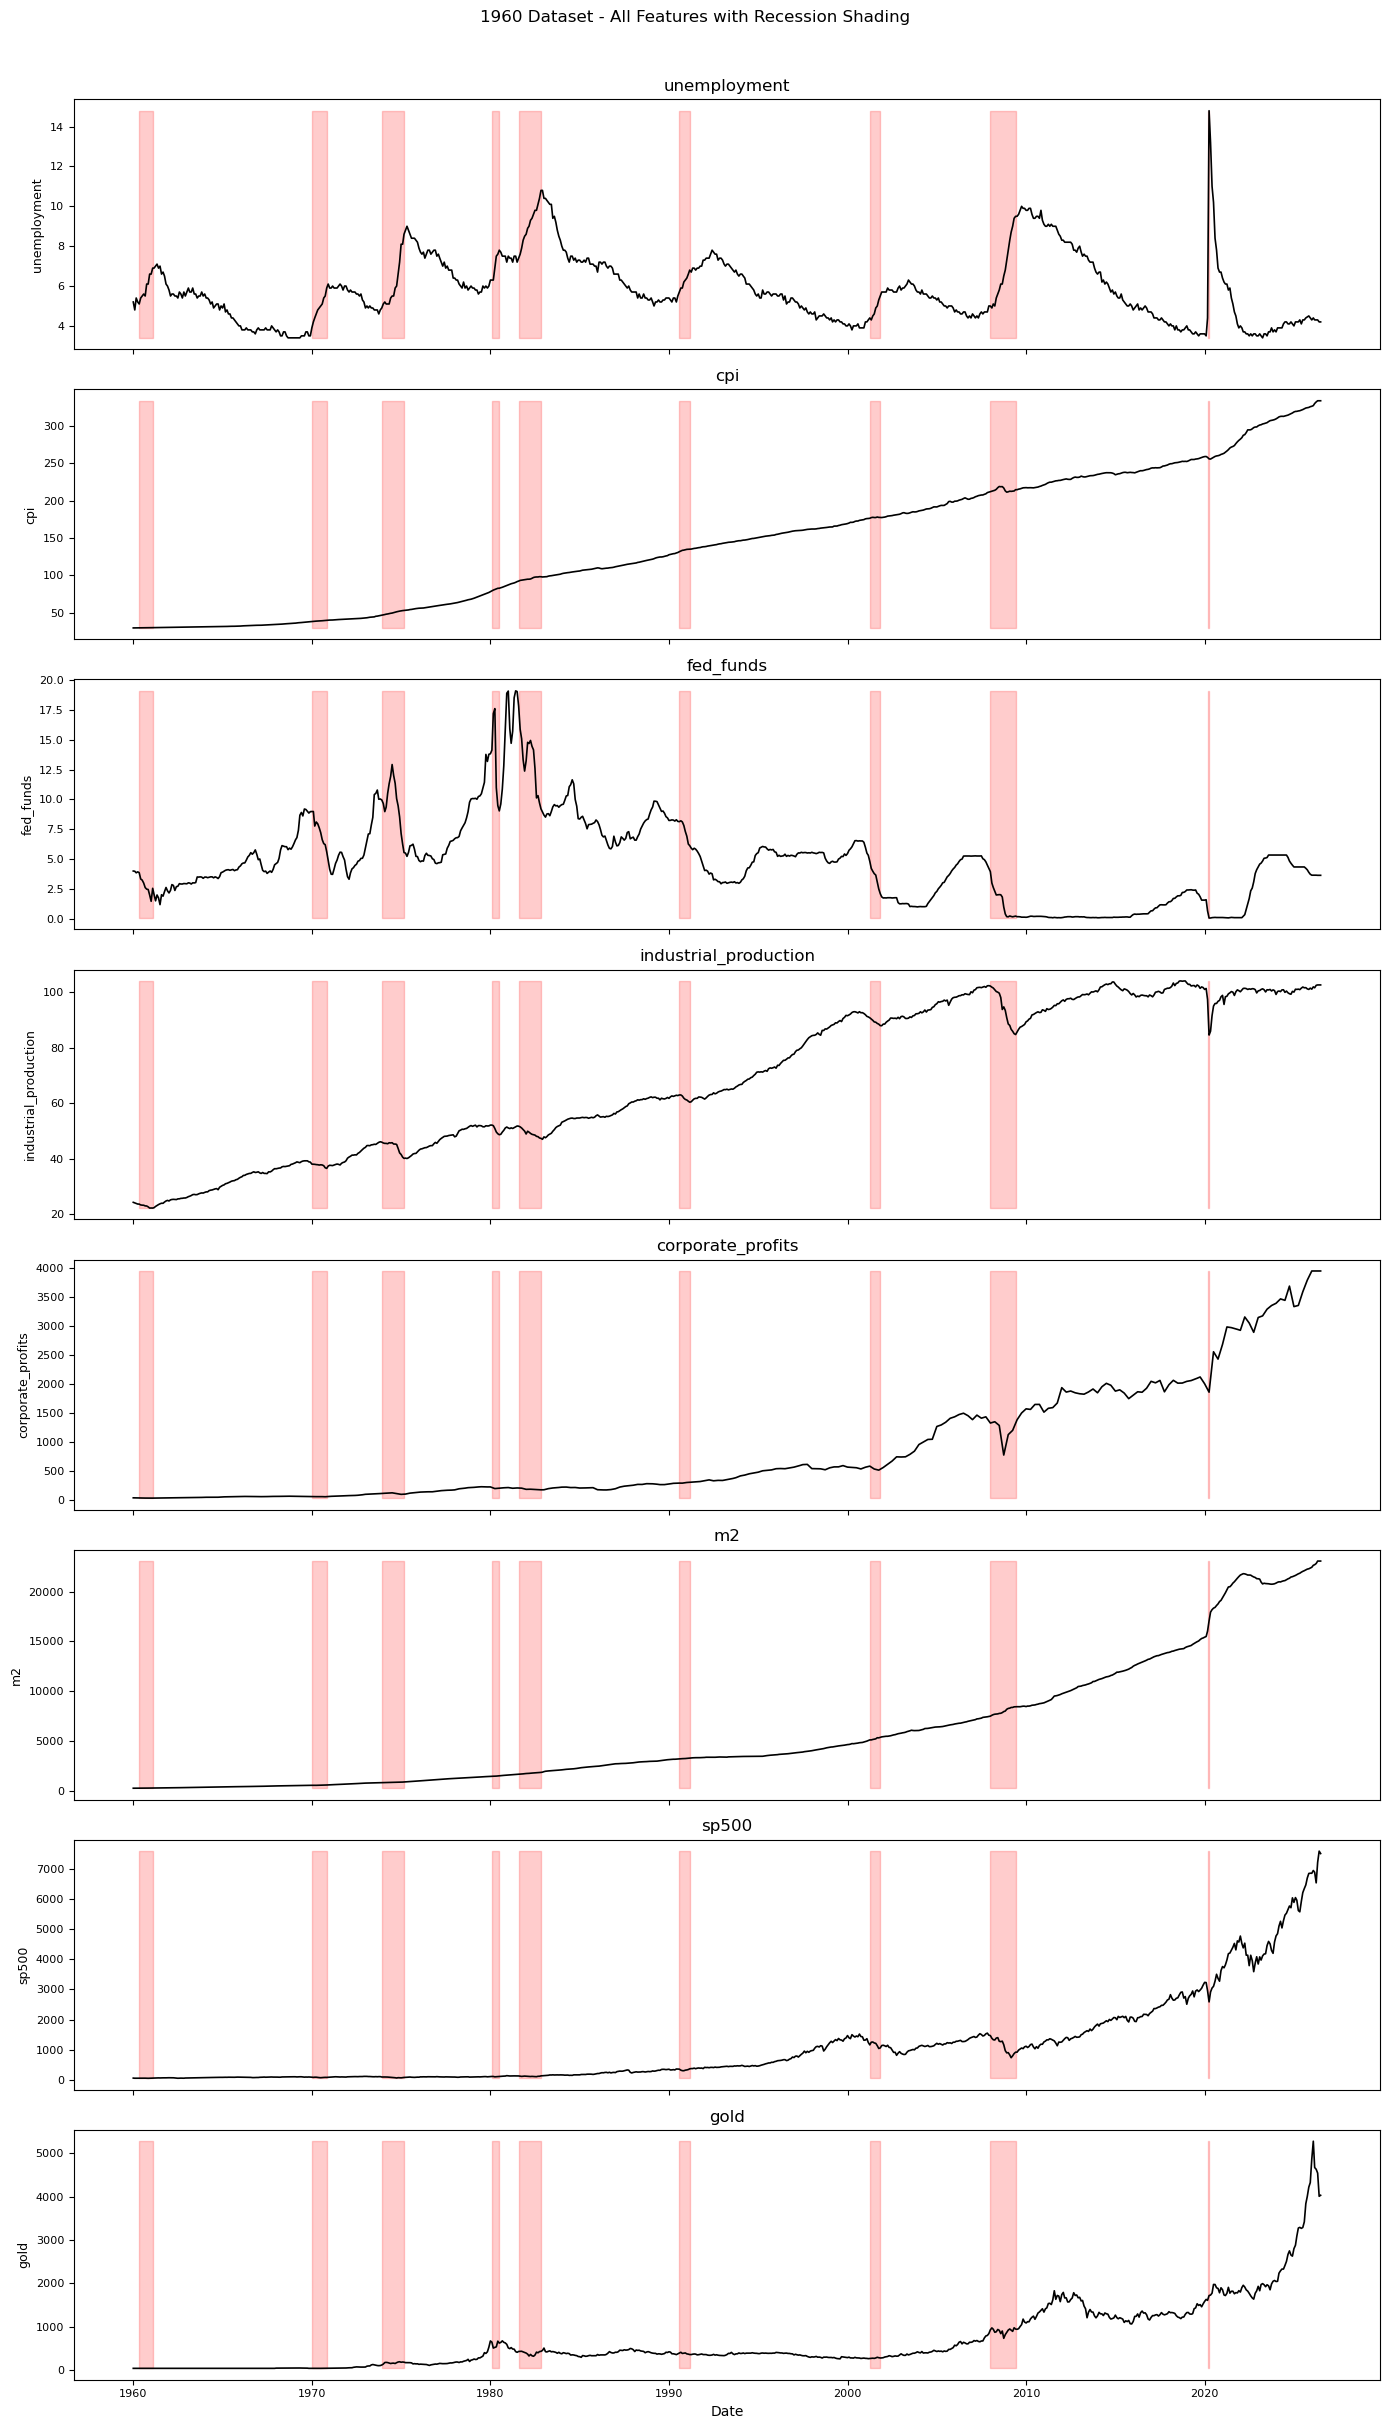

In [24]:
# Time Series Plots - 1960 Dataset

features_1960_plot = [c for c in df_1960.columns if c != "recession"]

fig, axes = plt.subplots(len(features_1960_plot), 1,
                          figsize=(14, 3 * len(features_1960_plot)), sharex=True)

for ax, feat in zip(axes, features_1960_plot):
    ax.plot(df_1960.index, df_1960[feat], color="black", linewidth=1.2)
    ax.fill_between(df_1960.index, df_1960[feat].min(), df_1960[feat].max(),
                    where=(df_1960["recession"] == 1), color="red", alpha=0.2)
    ax.set_title(feat)
    ax.set_ylabel(feat, fontsize=9)
    ax.tick_params(labelsize=8)

axes[-1].set_xlabel("Date")
fig.suptitle("1960 Dataset - All Features with Recession Shading", fontsize=12, y=1.01)
plt.tight_layout()
plt.show()

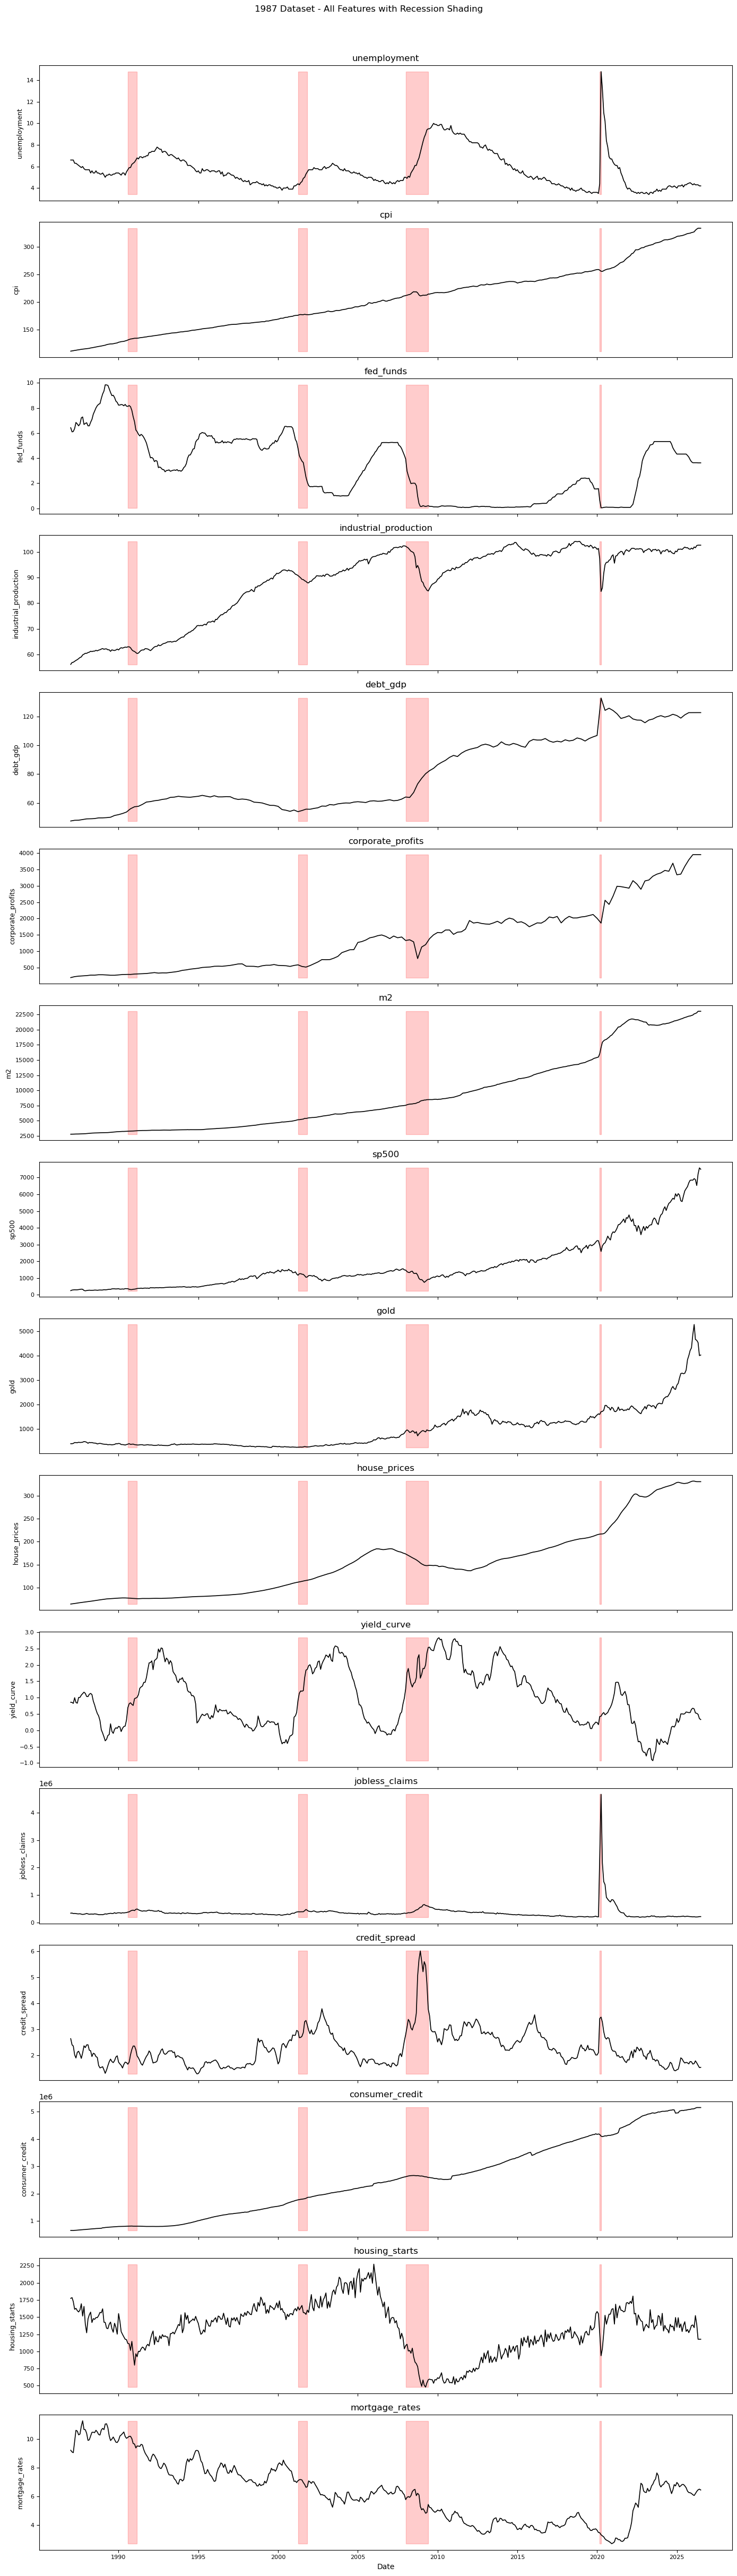

In [25]:
# Time Series Plots - 1987 Dataset 

features_1987_plot = [c for c in df_1987.columns if c != "recession"]

fig, axes = plt.subplots(len(features_1987_plot), 1,
                          figsize=(14, 3 * len(features_1987_plot)), sharex=True)

for ax, feat in zip(axes, features_1987_plot):
    ax.plot(df_1987.index, df_1987[feat], color="black", linewidth=1.2)
    ax.fill_between(df_1987.index, df_1987[feat].min(), df_1987[feat].max(),
                    where=(df_1987["recession"] == 1), color="red", alpha=0.2)
    ax.set_title(feat)
    ax.set_ylabel(feat, fontsize=9)
    ax.tick_params(labelsize=8)

axes[-1].set_xlabel("Date")
fig.suptitle("1987 Dataset - All Features with Recession Shading", fontsize=12, y=1.01)
plt.tight_layout()
plt.show()